In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from scipy.spatial.distance import cdist
from collections import Counter

In [3]:
centers = np.array([
    [-20, -20, -20],
    [ 20, -20, -20],
    [-20,  20,  20],
    [ 20,  20, -20]
])

X, y = make_blobs(
    n_samples=4000,
    centers=centers,
    cluster_std=[2.5, 3.7, 6.0, 1.4],
    random_state=42
)

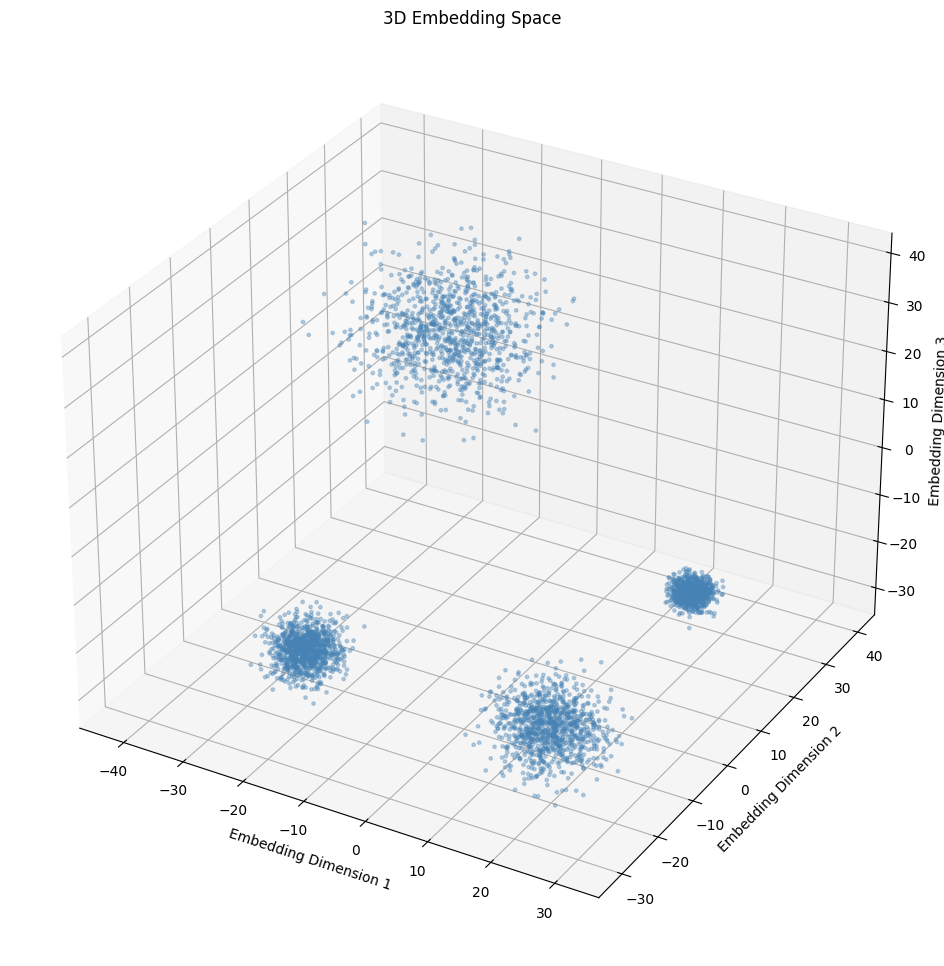

In [9]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(12, 12))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    X[:,0],
    X[:,1],
    X[:,2],
    color="steelblue",
    s=6,
    alpha=0.35
)

ax.set_title("3D Embedding Space")
ax.set_xlabel("Embedding Dimension 1")
ax.set_ylabel("Embedding Dimension 2")
ax.set_zlabel("Embedding Dimension 3")

plt.show()

### GNG


One knob worth playing with once you've got it running: min_quota_frac (currently 0.6). Lower it and you'll drift back toward vanilla GNG's skew; raise it toward 1.0 and you'll force near-perfectly equal coverage regardless of how each domain's actual difficulty differs. For the real project, that's the exact same knob you'll tune per real model-domain later — worth treating as a hyperparameter you report a sweep over, not a fixed constant.

In [5]:
class LabelAwareGNG:
    def __init__(self, max_nodes=150, max_age=40, lambda_step=100,
                 eps_b=0.05, eps_n=0.006, alpha=0.5, beta=0.995,
                 min_quota_frac=0.6):
        self.max_nodes = max_nodes
        self.max_age = max_age
        self.lambda_step = lambda_step
        self.eps_b = eps_b
        self.eps_n = eps_n
        self.alpha = alpha
        self.beta = beta
        self.min_quota_frac = min_quota_frac  # floor each label gets before free-for-all growth
        
    def fit(self, X, y):
        rng = np.random.default_rng(42)
        labels = np.unique(y)
        n_labels = len(labels)
        self.equal_share = self.max_nodes / n_labels
        self.min_quota = self.min_quota_frac * self.equal_share

        # seed ONE node per label instead of 2 random points
        self.weights, self.errors, self.node_label = {}, {}, {}
        next_node = 0
        for lab in labels:
            idx = rng.choice(np.where(y == lab)[0])
            self.weights[next_node] = X[idx].copy()
            self.errors[next_node] = 0.0
            self.node_label[next_node] = lab
            next_node += 1

        self.edges = {}  # no cross-label seed ring - each label starts as its own component

        iteration = 0
        while len(self.weights) < self.max_nodes:
            i = rng.integers(len(X))
            x, x_label = X[i], y[i]

            # only compete against nodes of THIS point's own label
            node_ids = [n for n in self.weights if self.node_label[n] == x_label]
            if len(node_ids) < 2:
                node_ids = list(self.weights.keys())  # fallback: label still has <2 nodes
            W = np.array([self.weights[n] for n in node_ids])
            d = np.linalg.norm(W - x, axis=1)
            order = np.argsort(d)
            s1 = node_ids[order[0]]
            s2 = node_ids[order[1]] if len(node_ids) > 1 else s1

            self.errors[s1] += d[order[0]] ** 2
            self.weights[s1] += self.eps_b * (x - self.weights[s1])
            for edge in list(self.edges.keys()):
                if s1 in edge:
                    other = edge[0] if edge[1] == s1 else edge[1]
                    if self.node_label.get(other) == self.node_label.get(s1):
                        self.weights[other] += self.eps_n * (x - self.weights[other])
                    self.edges[edge] += 1
            if s2 != s1:
                self.edges[tuple(sorted((s1, s2)))] = 0
            for edge in list(self.edges.keys()):
                if self.edges[edge] > self.max_age:
                    del self.edges[edge]

            connected = set()
            for a, b in self.edges:
                connected.add(a); connected.add(b)
            label_node_counts = Counter(self.node_label.values())
            for node in list(self.weights.keys()):
                lab = self.node_label[node]
                if node not in connected and label_node_counts[lab] > 1:
                    del self.weights[node]; del self.errors[node]; del self.node_label[node]
                    label_node_counts[lab] -= 1

            # --- insertion: THIS is a top-level step in the while loop,
            # NOT nested inside the pruning loop above ---
            if iteration % self.lambda_step == 0 and len(self.weights) < self.max_nodes:
                counts = Counter(self.node_label.values())
                starving = [lab for lab in labels if counts.get(lab, 0) < self.min_quota]

                if starving:
                    target_label = min(starving, key=lambda l: counts.get(l, 0))
                    candidates = [n for n in self.errors if self.node_label[n] == target_label]
                    q = max(candidates, key=lambda n: self.errors[n])
                else:
                    q = max(self.errors, key=self.errors.get)
                    target_label = self.node_label[q]

                neighbors = [b for a, b in self.edges if a == q] + \
                            [a for a, b in self.edges if b == q]
                same_label_neighbors = [n for n in neighbors if self.node_label.get(n) == target_label]

                if same_label_neighbors:
                    f = max(same_label_neighbors, key=lambda n: self.errors[n])
                    new = (self.weights[q] + self.weights[f]) / 2
                    self.weights[next_node] = new
                    self.errors[next_node] = (self.errors[q] + self.errors[f]) / 2
                    self.node_label[next_node] = target_label
                    edge = tuple(sorted((q, f)))
                    if edge in self.edges:
                        del self.edges[edge]
                    self.edges[tuple(sorted((q, next_node)))] = 0
                    self.edges[tuple(sorted((f, next_node)))] = 0
                    self.errors[q] *= self.alpha
                    self.errors[f] *= self.alpha
                    next_node += 1
                else:
                    own_idx = np.where(y == target_label)[0]
                    own_pts = X[own_idx]
                    same_label_nodes = [n for n in self.weights if self.node_label[n] == target_label]
                    W_same = np.array([self.weights[n] for n in same_label_nodes])
                    dmat = np.linalg.norm(own_pts[:, None, :] - W_same[None, :, :], axis=2)
                    nearest = dmat.min(axis=1)
                    worst = np.argmax(nearest)
                    self.weights[next_node] = own_pts[worst].copy()
                    self.errors[next_node] = 0.0
                    self.node_label[next_node] = target_label
                    self.edges[tuple(sorted((q, next_node)))] = 0
                    self.errors[q] *= self.alpha
                    next_node += 1

            for k in self.errors:
                self.errors[k] *= self.beta
            iteration += 1

        return self

In [6]:
gng = LabelAwareGNG(max_nodes=150, lambda_step=100)
gng.fit(X, y)

### Viz

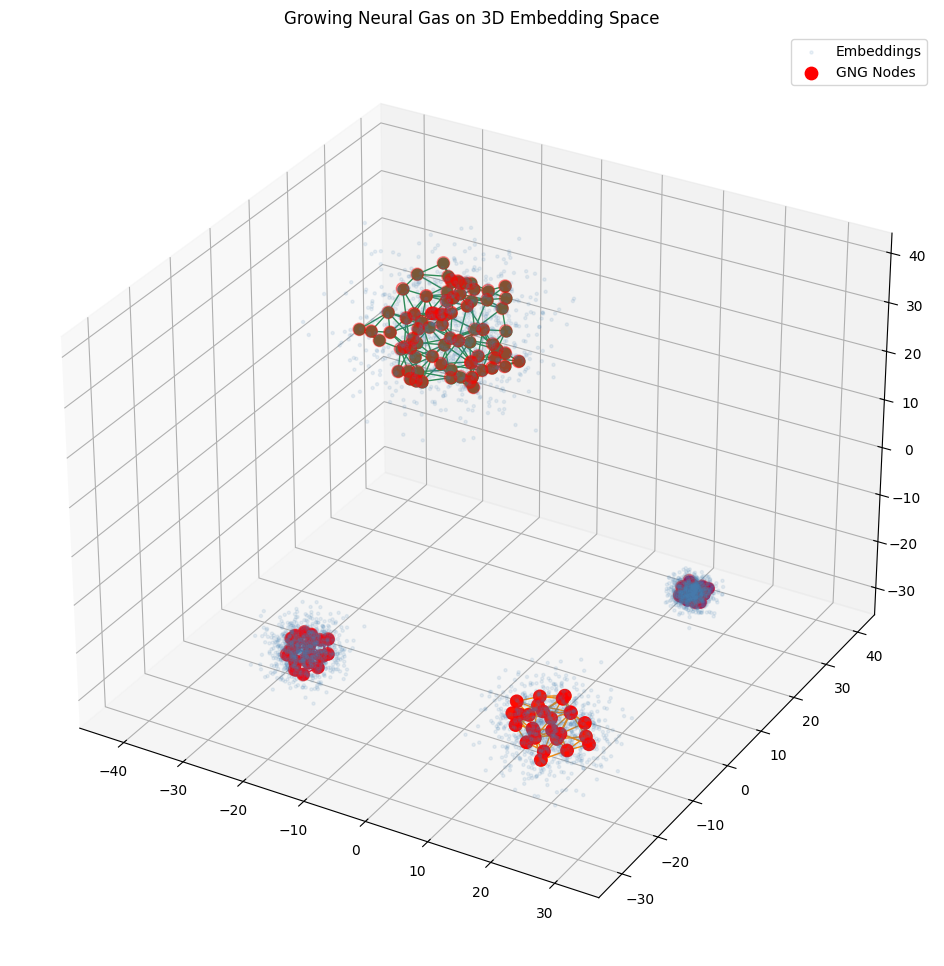

In [10]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(12,12))
ax = fig.add_subplot(111, projection='3d')

# Original data (pretend these are embeddings)
ax.scatter(
    X[:,0],
    X[:,1],
    X[:,2],
    s=5,
    alpha=0.1,
    color="steelblue",
    label="Embeddings"
)

# Draw GNG edges
colors = {0: "crimson", 1: "darkorange", 2: "seagreen", 3: "purple"}
for nid, w in gng.weights.items():
    ax.scatter(*w, color=colors[gng.node_label[nid]], s=60)
for (a, b) in gng.edges:
    if gng.node_label[a] == gng.node_label[b]:
        p1, p2 = gng.weights[a], gng.weights[b]
        ax.plot([p1[0],p2[0]], [p1[1],p2[1]], [p1[2],p2[2]],
                color=colors[gng.node_label[a]], linewidth=1)

# Draw GNG nodes
pins = np.array(list(gng.weights.values()))

ax.scatter(
    pins[:,0],
    pins[:,1],
    pins[:,2],
    color="red",
    s=80,
    label="GNG Nodes"
)

ax.set_title("Growing Neural Gas on 3D Embedding Space")
ax.legend()

plt.show()

In [8]:
# print("Nodes :", len(gng.weights))
# print("Edges :", len(gng.edges))

print("Nodes per label:", Counter(gng.node_label.values()))

Nodes per label: Counter({np.int64(2): 78, np.int64(1): 26, np.int64(0): 23, np.int64(3): 23})
